In [1]:
import pickle, math
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np

In [3]:
datafile_path = "./taskdata/task_statistics_2023-01-04-03-11-15.pkl"
data = pickle.load(open(datafile_path, "rb"))

In [10]:
def task_scatter(task_statistics, datafile='taskdata.pkl'):
    """
    Use matlibplot to draw a scatter plot of the finished time of each task, X-axis is the timeline, Y-axis is the finished time.
    Finished task is marked as blue circle, missing deadline task is marked as red x.
    task_statistics: defaultdict(TaskFinishedObject), each dict contains the information of a task
    dict_values([{'taskid': 'Period[0]_#39_Id[1]', 'release_time': 0.9750000000000001, 'deadline': 0.9850000000000001, 'priority': 1, 'dependency': [], 'res': 'success', 'start_time': '0.9760010242462158', 'end_time': '0.9840006828308105'}])
    """
    handlerid2color = ["_","blue","red","orange","green","black","purple","magenta"]
    handler2points = defaultdict(dict)
    for handler_id in range(1,5):
        handler2points[handler_id] = {
            'finished_x': [],
            'finished_y': [],
            'missing_x': [],
            'missing_y': [],
            'skip_x': [],
            'skip_y': []
        }

    # Iterate over the task statistics dictionary
    for task, task_info in task_statistics.items():
        handler_id = task_info["handler_id"]
        release_time = float(task_info['release_time'])
        end_time = float(task_info['end_time'])
        if(release_time<=1):
            continue
        # If the task was finished on time, add its start time and end time to the finished lists
        if task_info['res'] == 'success':
            handler2points[handler_id]["finished_x"].append(end_time-1)
            handler2points[handler_id]["finished_y"].append(1000*(end_time - release_time))
        # If the task missed its deadline, add its release time and deadline to the missed lists
        elif task_info['res'] == 'failure':
            handler2points[handler_id]["missing_x"].append(end_time-1)
            handler2points[handler_id]["missing_y"].append(1000*(end_time - release_time))
        elif task_info["res"] == "skip":
            handler2points[handler_id]["skip_x"].append(release_time-1)
            handler2points[handler_id]["skip_y"].append(end_time - release_time)
    
    
    # Create a figure and axis object using Matplotlib
    fig, ax = plt.subplots()
    finish_handles = []
    missing_handles = []
    skip_handles = []

    id2name = {
        1: "A",
        2: "B",
        3: "D",
        4: "C"
    }

    for handler_id in [1,2,3,4]:
        if(len(handler2points[handler_id]["finished_x"]) == 0 and len(handler2points[handler_id]["missing_x"]) == 0 and len(handler2points[handler_id]["skip_x"]) == 0):
            continue
        # Plot the finished tasks as blue circles
        finished_scatter = ax.scatter(handler2points[handler_id]["finished_x"], handler2points[handler_id]["finished_y"], c = handlerid2color[handler_id], marker='o', s = 15, label= f"{id2name[handler_id]}")
        missing_scatter = ax.scatter(handler2points[handler_id]["missing_x"], handler2points[handler_id]["missing_y"], c = handlerid2color[handler_id], marker='x', s = 50)
        skiped_scatter = ax.scatter(handler2points[handler_id]["skip_x"], handler2points[handler_id]["skip_y"], c = handlerid2color[handler_id], marker='+', s = 50) 
        missing_deadline_rate = len(handler2points[handler_id]["missing_x"]) / (len(handler2points[handler_id]["finished_x"]) + len(handler2points[handler_id]["missing_x"]) + len(handler2points[handler_id]["skip_x"]))
        finished_rate = len(handler2points[handler_id]["finished_x"]) / (len(handler2points[handler_id]["finished_x"]) + len(handler2points[handler_id]["missing_x"]) + len(handler2points[handler_id]["skip_x"]))
        skip_rate = len(handler2points[handler_id]["skip_x"]) / (len(handler2points[handler_id]["finished_x"]) + len(handler2points[handler_id]["missing_x"]) + len(handler2points[handler_id]["skip_x"]))
        finish_handles.append(finished_scatter)
        missing_handles.append(missing_scatter)
        skip_handles.append(skiped_scatter)
        print('Statistics of handler ', handler_id, ':')
        print('missing deadline rate: ', missing_deadline_rate)
        print('finished rate: ', finished_rate)
        print('skip rate: ', skip_rate)

    ax.legend(loc="upper left", title="Task Name")
    # ax.legend(['Finished', 'Missed', 'Dropped'], loc="upper right", title="Task Status")
    # ax.legend(['o', 'x', '+'], ['Finished', 'Missed', 'Skip'], loc="upper right", title="Task Status")
    # Set the X and Y axis labels
    ax.set_xlabel('Timeline [s]')
    ax.set_ylabel('Response Time [ms]')
    plt.title("Dynamic Workloads Tasks Pipeline")
    
    # Show the plot
    plt.show()


Statistics of handler  1 :
missing deadline rate:  0.0
finished rate:  1.0
skip rate:  0.0
Statistics of handler  2 :
missing deadline rate:  0.17557251908396945
finished rate:  0.7175572519083969
skip rate:  0.10687022900763359


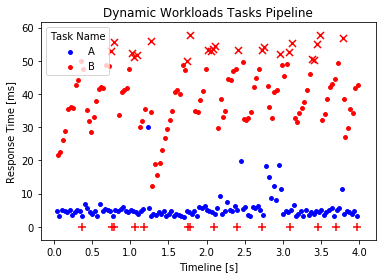

In [11]:
task_scatter(data)

In [80]:
datafile_path = "./taskdata/task_statistics_2023-01-03-01-12-17.pkl"
data2 = pickle.load(open(datafile_path, "rb"))


In [79]:
def task_boxplot(task_statistics, datafile='taskdata.pkl'):
    """
    Use matlibplot to draw a scatter plot of the finished time of each task, X-axis is the timeline, Y-axis is the finished time.
    Finished task is marked as blue circle, missing deadline task is marked as red x.
    task_statistics: defaultdict(TaskFinishedObject), each dict contains the information of a task
    dict_values([{'taskid': 'Period[0]_#39_Id[1]', 'release_time': 0.9750000000000001, 'deadline': 0.9850000000000001, 'priority': 1, 'dependency': [], 'res': 'success', 'start_time': '0.9760010242462158', 'end_time': '0.9840006828308105'}])
    """
    handlerid2color = ["_","blue","red","orange","purple","black","cyan","magenta"]
    handler2points = defaultdict(dict)
    handler2boxdata = defaultdict(dict)
    for handler_id in range(1,5):
        handler2points[handler_id] = {
            'finished_x': [],
            'finished_y': [],
            'missing_x': [],
            'missing_y': [],
            'skip_x': [],
            'skip_y': []
        }
        handler2boxdata[handler_id] = []

    # Iterate over the task statistics dictionary
    for task, task_info in task_statistics.items():
        handler_id = task_info["handler_id"]
        # If the task was finished on time, add its start time and end time to the finished lists
        release_time = float(task_info['release_time'])
        end_time = float(task_info['end_time'])
        if task_info['res'] == 'success':
            handler2points[handler_id]["finished_x"].append(end_time)
            handler2points[handler_id]["finished_y"].append(1000*(end_time - release_time))
        # If the task missed its deadline, add its release time and deadline to the missed lists
        elif task_info['res'] == 'failure':
            handler2points[handler_id]["missing_x"].append(end_time)
            handler2points[handler_id]["missing_y"].append(1000*(end_time - release_time))
        elif task_info["res"] == "skip":
            handler2points[handler_id]["skip_x"].append(release_time)
            handler2points[handler_id]["skip_y"].append(0)
        # box data group by release time per seconds
        if(math.floor(release_time) >= len(handler2boxdata[handler_id])):
            handler2boxdata[handler_id].append([])
        # 按release time每秒聚类
        handler2boxdata[handler_id][math.floor(release_time)].append(1000*(end_time - release_time))
    
    # print('handler box data', handler2boxdata)
    # Create a figure and axis object using Matplotlib
    fig, ax = plt.subplots()
    finish_handles = []
    missing_handles = []
    skip_handles = []

    for handler_id in [1,2,3,4]:
        if(len(handler2points[handler_id]["finished_x"]) == 0 and len(handler2points[handler_id]["missing_x"]) == 0 and len(handler2points[handler_id]["skip_x"]) == 0):
            continue
        # Plot the finished tasks as blue circles
        
        ax.boxplot(handler2boxdata[handler_id])
        # ax.set_xticklabels(range(1,len(handler2boxdata[handler_id])))

        missing_deadline_rate = len(handler2points[handler_id]["missing_x"]) / (len(handler2points[handler_id]["finished_x"]) + len(handler2points[handler_id]["missing_x"]) + len(handler2points[handler_id]["skip_x"]))
        finished_rate = len(handler2points[handler_id]["finished_x"]) / (len(handler2points[handler_id]["finished_x"]) + len(handler2points[handler_id]["missing_x"]) + len(handler2points[handler_id]["skip_x"]))
        skip_rate = len(handler2points[handler_id]["skip_x"]) / (len(handler2points[handler_id]["finished_x"]) + len(handler2points[handler_id]["missing_x"]) + len(handler2points[handler_id]["skip_x"]))
        print('Statistics of handler ', handler_id, ':')
        print('missing deadline rate: ', missing_deadline_rate)
        print('finished rate: ', finished_rate)
        print('skip rate: ', skip_rate)

    # ax.legend(loc="upper right", title="Handler ID")
    # ax.legend(['Finished', 'Missed', 'Skip'], loc="upper right", title="Task Status")
    # Set the X and Y axis labels
    ax.set_xlabel('Timeline [s]')
    ax.set_ylabel('Response Time [ms]')
    # ax.set_ylim(0, 0.05)
    plt.title("Async Inference Tasks")
    
    # Show the plot
    plt.show()

    # plt.savefig(f'./taskdata_figure/{datafile}.pdf') 

Statistics of handler  1 :
missing deadline rate:  0.013333333333333334
finished rate:  0.9866666666666667
skip rate:  0.0
Statistics of handler  2 :
missing deadline rate:  0.19393939393939394
finished rate:  0.6242424242424243
skip rate:  0.18181818181818182


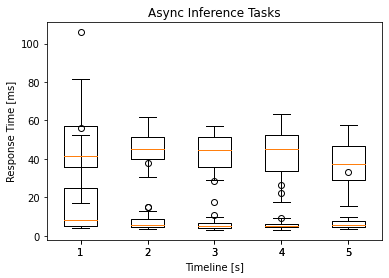

In [81]:
task_boxplot(data2, 'Async Inference Tasks')

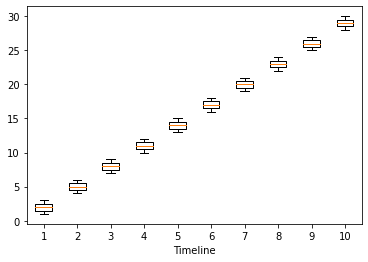

In [22]:
import matplotlib.pyplot as plt
# Create a list of lists, where each inner list represents the data for a given second
data = [[1, 2, 3], [4, 5, 6], [7, 8, 9], [10, 11, 12], [13, 14, 15], [16, 17, 18], [19, 20, 21], [22, 23, 24], [25, 26, 27], [28, 29, 30]]

# Create a figure and axis object using Matplotlib
fig, ax = plt.subplots()

# Plot the data as a boxplot
ax.boxplot(data)

# Set the X-axis labels to the seconds of time
ax.set_xticklabels(range(1, 11))

# Set the X-axis label to 'Timeline'
ax.set_xlabel('Timeline')

# Show the plot
plt.show()

In [12]:
from matplotlib import font_manager

In [13]:
for font in font_manager.fontManager.ttflist:
    print(font.name, '-', font.fname)

DejaVu Sans - C:\Users\RenTao\.conda\envs\py36\lib\site-packages\matplotlib\mpl-data\fonts\ttf\DejaVuSans-BoldOblique.ttf
STIXSizeOneSym - C:\Users\RenTao\.conda\envs\py36\lib\site-packages\matplotlib\mpl-data\fonts\ttf\STIXSizOneSymReg.ttf
STIXGeneral - C:\Users\RenTao\.conda\envs\py36\lib\site-packages\matplotlib\mpl-data\fonts\ttf\STIXGeneralBolIta.ttf
STIXSizeFourSym - C:\Users\RenTao\.conda\envs\py36\lib\site-packages\matplotlib\mpl-data\fonts\ttf\STIXSizFourSymReg.ttf
DejaVu Serif - C:\Users\RenTao\.conda\envs\py36\lib\site-packages\matplotlib\mpl-data\fonts\ttf\DejaVuSerif.ttf
DejaVu Sans - C:\Users\RenTao\.conda\envs\py36\lib\site-packages\matplotlib\mpl-data\fonts\ttf\DejaVuSans.ttf
DejaVu Serif - C:\Users\RenTao\.conda\envs\py36\lib\site-packages\matplotlib\mpl-data\fonts\ttf\DejaVuSerif-BoldItalic.ttf
STIXNonUnicode - C:\Users\RenTao\.conda\envs\py36\lib\site-packages\matplotlib\mpl-data\fonts\ttf\STIXNonUniBol.ttf
STIXSizeThreeSym - C:\Users\RenTao\.conda\envs\py36\lib\site

In [7]:
def task_scatter2(task_statistics, datafile='taskdata.pkl'):
    """
    For case study 2
    Use matlibplot to draw a scatter plot of the finished time of each task, X-axis is the timeline, Y-axis is the finished time.
    Finished task is marked as blue circle, missing deadline task is marked as red x.
    task_statistics: defaultdict(TaskFinishedObject), each dict contains the information of a task
    dict_values([{'taskid': 'Period[0]_#39_Id[1]', 'release_time': 0.9750000000000001, 'deadline': 0.9850000000000001, 'priority': 1, 'dependency': [], 'res': 'success', 'start_time': '0.9760010242462158', 'end_time': '0.9840006828308105'}])
    """
    handlerid2color = ["_","blue","red","orange","green","black","purple","magenta"]
    handler2points = defaultdict(dict)
    for handler_id in range(1,5):
        handler2points[handler_id] = {
            'finished_x': [],
            'finished_y': [],
            'missing_x': [],
            'missing_y': [],
            'skip_x': [],
            'skip_y': []
        }
    missing_and_drop_step1 = []
    missing_and_drop_step2 = []
    missing_and_drop_step3 = []
    missing_and_drop_persecond = defaultdict(list)
    success_persecond = defaultdict(list)
    for handler_id in range(1,5):
        missing_and_drop_persecond[handler_id] = defaultdict(list)
        success_persecond[handler_id] = defaultdict(list)
    # Iterate over the task statistics dictionary
    for task, task_info in task_statistics.items():
        handler_id = task_info["handler_id"]
        release_time = float(task_info['release_time'])
        end_time = float(task_info['end_time'])

        # If the task was finished on time, add its start time and end time to the finished lists
        if task_info['res'] == 'success':
            handler2points[handler_id]["finished_x"].append(end_time)
            handler2points[handler_id]["finished_y"].append(1000*(end_time - release_time))
            success_persecond[handler_id][math.floor(release_time)].append(1)
        # If the task missed its deadline, add its release time and deadline to the missed lists
        elif task_info['res'] == 'failure':
            handler2points[handler_id]["missing_x"].append(end_time)
            handler2points[handler_id]["missing_y"].append(1000*(end_time - release_time))
            missing_and_drop_persecond[handler_id][math.floor(release_time)].append(1)
        elif task_info["res"] == "skip":
            handler2points[handler_id]["skip_x"].append(release_time)
            handler2points[handler_id]["skip_y"].append(end_time - release_time)
            missing_and_drop_persecond[handler_id][math.floor(release_time)].append(1)
    
    
    
    for handler_id in range(1,5):
        print(f'missing and drop rate per sercond handler[{handler_id}]:')
        for i in range(10):
            if(len(success_persecond[handler_id][i]) + len(missing_and_drop_persecond[handler_id][i]) == 0):
                print(f'no task on running on {i} - {i+1} second')
                continue
            print(f'missing rate on {i} - {i+1} second: {len(missing_and_drop_persecond[handler_id][i])/(len(success_persecond[handler_id][i]) + len(missing_and_drop_persecond[handler_id][i]))}')
    
    # Create a figure and axis object using Matplotlib
    fig, ax = plt.subplots()
    finish_handles = []
    missing_handles = []
    skip_handles = []

    id2name = {
        1: "A",
        2: "C",
        3: "D",
        4: "B"
    }

    for handler_id in [1,2,3,4]:
        if(len(handler2points[handler_id]["finished_x"]) == 0 and len(handler2points[handler_id]["missing_x"]) == 0 and len(handler2points[handler_id]["skip_x"]) == 0):
            continue
        # Plot the finished tasks as blue circles
        finished_scatter = ax.scatter(handler2points[handler_id]["finished_x"], handler2points[handler_id]["finished_y"], c = handlerid2color[handler_id], marker='o', s = 15, label= f"{id2name[handler_id]}")
        missing_scatter = ax.scatter(handler2points[handler_id]["missing_x"], handler2points[handler_id]["missing_y"], c = handlerid2color[handler_id], marker='x', s = 50)
        skiped_scatter = ax.scatter(handler2points[handler_id]["skip_x"], handler2points[handler_id]["skip_y"], c = handlerid2color[handler_id], marker='+', s = 50) 
        missing_deadline_rate = len(handler2points[handler_id]["missing_x"]) / (len(handler2points[handler_id]["finished_x"]) + len(handler2points[handler_id]["missing_x"]) + len(handler2points[handler_id]["skip_x"]))
        finished_rate = len(handler2points[handler_id]["finished_x"]) / (len(handler2points[handler_id]["finished_x"]) + len(handler2points[handler_id]["missing_x"]) + len(handler2points[handler_id]["skip_x"]))
        skip_rate = len(handler2points[handler_id]["skip_x"]) / (len(handler2points[handler_id]["finished_x"]) + len(handler2points[handler_id]["missing_x"]) + len(handler2points[handler_id]["skip_x"]))
        finish_handles.append(finished_scatter)
        missing_handles.append(missing_scatter)
        skip_handles.append(skiped_scatter)
        print('Statistics of handler ', handler_id, ':')
        print('missing deadline rate: ', missing_deadline_rate)
        print('finished rate: ', finished_rate)
        print('skip rate: ', skip_rate)

    # ax.legend(loc="upper right", title="Task Name")
    # ax.legend(['Finished', 'Missed', 'Dropped'], loc="upper right", title="Task Status")
    # ax.legend(['o', 'x', '+'], ['Finished', 'Missed', 'Skip'], loc="upper right", title="Task Status")
    ax.set_ylim(0, 50)
    ax.set_xlim(0, 9)
    # ax.set_xticks(np.arange(0, 10, 1))
    # Set the X and Y axis labels
    ax.set_xlabel('Timeline [s]')
    ax.set_ylabel('Response Time [ms]')
    plt.title("Dependent Inference")
    
    # Show the plot
    plt.show()


In [8]:
datafile_path = "./taskdata/dynamic_workloads_9s_good_present.pkl"
data3 = pickle.load(open(datafile_path, "rb"))

missing and drop rate per sercond handler[1]:
missing rate on 0 - 1 second: 0.0
missing rate on 1 - 2 second: 0.0
missing rate on 2 - 3 second: 0.0
missing rate on 3 - 4 second: 0.0
missing rate on 4 - 5 second: 0.0
missing rate on 5 - 6 second: 0.0
missing rate on 6 - 7 second: 0.0
missing rate on 7 - 8 second: 0.0
missing rate on 8 - 9 second: 0.0
no task on running on 9 - 10 second
missing and drop rate per sercond handler[2]:
missing rate on 0 - 1 second: 0.13333333333333333
missing rate on 1 - 2 second: 0.0
missing rate on 2 - 3 second: 0.03333333333333333
missing rate on 3 - 4 second: 0.3
missing rate on 4 - 5 second: 0.03333333333333333
missing rate on 5 - 6 second: 0.06666666666666667
missing rate on 6 - 7 second: 0.03333333333333333
missing rate on 7 - 8 second: 0.03333333333333333
missing rate on 8 - 9 second: 0.0
no task on running on 9 - 10 second
missing and drop rate per sercond handler[3]:
no task on running on 0 - 1 second
no task on running on 1 - 2 second
no task on r

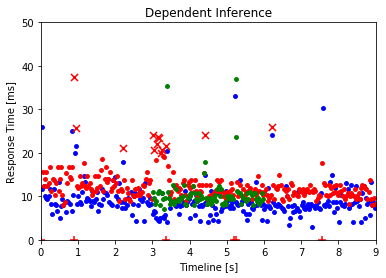

0.12999999999999998

In [10]:
task_scatter2(data3)
(0.3+0.03+0.06)/3